# Ridge Linear Regression

In [1]:
# Import the libraries used to load the dataset, fit ridge regression, evaluate it, and plot results.

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("default")

## 1. Load the dataset

In [2]:
# Load YachtHydrodynamics.csv and preview the observations.
df = pd.read_csv("YachtHydrodynamics.csv")

print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
display(df.head())

Dataset shape: 308 rows × 7 columns


,"Longitudinal position of the center of buoyancy, adimensional",Prismatic coefficient,Length-displacement ratio,Beam-draught ratio,Length-beam ratio,Froude number,Residuary resistance per unit weight of displacement
0,-2.3,0.568,4.78,3.99,3.17,0.125,0.11
1,-2.3,0.568,4.78,3.99,3.17,0.150,0.27
2,-2.3,0.568,4.78,3.99,3.17,0.175,0.47
3,-2.3,0.568,4.78,3.99,3.17,0.200,0.78
4,-2.3,0.568,4.78,3.99,3.17,0.225,1.18


## 2. Check dataset structure and missing values

In [3]:
# Report the column names, data types, and missing values.

print("Columns in the dataset:")

for column_number, column_name in enumerate(df.columns, start=1):
    print(f"{column_number}. {column_name}")

Columns in the dataset:
1. Longitudinal position of the center of buoyancy, adimensional
2. Prismatic coefficient
3. Length-displacement ratio
4. Beam-draught ratio
5. Length-beam ratio
6. Froude number
7. Residuary resistance per unit weight of displacement


## 3. Separate predictors and target

In [4]:
# Convert the predictor columns and target column into NumPy arrays.
feature_names = list(df.columns[:-1])
target_name = df.columns[-1]

X = df.iloc[:, :-1].to_numpy(dtype=float)
y = df.iloc[:, -1].to_numpy(dtype=float)

print("Predictor matrix X shape:", X.shape)
print("Target vector y shape:", y.shape)
print("Target column:", target_name)
print("\nTarget summary statistics:")
print(pd.Series(y, name=target_name).describe())

Predictor matrix X shape: (308, 6)
Target vector y shape: (308,)
Target column: Residuary resistance per unit weight of displacement

Target summary statistics:
count    308.000000
mean      10.495357
std       15.160490
min        0.010000
25%        0.777500
50%        3.065000
75%       12.815000
max       62.420000
Name: Residuary resistance per unit weight of displacement, dtype: float64


## 4. Split the data into training and testing sets

In [5]:
# Create a reproducible 80/20 train-test split without using the test set for fitting.
random_generator = np.random.default_rng(42)
number_of_rows = X.shape[0]
shuffled_indices = random_generator.permutation(number_of_rows)

train_size = int(round(number_of_rows * 0.80))
train_indices = shuffled_indices[:train_size]
test_indices = shuffled_indices[train_size:]

X_train = X[train_indices]
X_test = X[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

print(f"Training observations: {len(y_train)} ({len(y_train) / number_of_rows:.1%})")
print(f"Testing observations:  {len(y_test)} ({len(y_test) / number_of_rows:.1%})")
print("Training feature matrix shape:", X_train.shape)
print("Testing feature matrix shape:", X_test.shape)

Training observations: 246 (79.9%)
Testing observations:  62 (20.1%)
Training feature matrix shape: (246, 6)
Testing feature matrix shape: (62, 6)


## 5. Standardize the predictors

In [6]:
# Standardize training and testing predictors using training-set statistics only.
feature_means = X_train.mean(axis=0)
feature_stds = X_train.std(axis=0)
feature_stds[feature_stds == 0] = 1.0  # Prevent division by zero for constant features.

X_train_scaled = (X_train - feature_means) / feature_stds
X_test_scaled = (X_test - feature_means) / feature_stds

print("Training-set feature means after standardization:")
print(np.round(X_train_scaled.mean(axis=0), 4))
print("\nTraining-set feature standard deviations after standardization:")
print(np.round(X_train_scaled.std(axis=0), 4))

Training-set feature means after standardization:
[-0.  0.  0. -0.  0.  0.]

Training-set feature standard deviations after standardization:
[1. 1. 1. 1. 1. 1.]


## 6. Fit the ridge regression model

In [7]:
# Fit ridge regression on the training set and print the fitted coefficients.
RIDGE_ALPHA = 0.001  # Regularization strength; larger values apply stronger shrinkage.

# Add the intercept column to the design matrices.
X_train_design = np.column_stack((np.ones(X_train_scaled.shape[0]), X_train_scaled))
X_test_design = np.column_stack((np.ones(X_test_scaled.shape[0]), X_test_scaled))

# Do not penalize the intercept, but penalize every feature coefficient.
penalty_matrix = np.eye(X_train_design.shape[1])
penalty_matrix[0, 0] = 0.0

# Solve the ridge normal equations: (X'X + alpha * P) beta = X'y.
normal_matrix = X_train_design.T @ X_train_design + RIDGE_ALPHA * penalty_matrix
right_hand_side = X_train_design.T @ y_train
beta = np.linalg.solve(normal_matrix, right_hand_side)

intercept = beta[0]
feature_coefficients = beta[1:]

print(f"Ridge regularization strength (alpha): {RIDGE_ALPHA}")
print(f"Intercept: {intercept:.6f}")
print("\nFeature coefficients (predictors are standardized):")
coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": feature_coefficients,
})
display(coefficient_table.round(6))

Ridge regularization strength (alpha): 0.001
Intercept: 10.142805

Feature coefficients (predictors are standardized):


,Feature,Coefficient
0,Longitudinal position of the center of buoyanc...,-0.257415
1,Prismatic coefficient,0.180946
2,Length-displacement ratio,1.165126
3,Beam-draught ratio,-1.072036
4,Length-beam ratio,-1.150462
5,Froude number,11.578721


## 7. Predict the target values

In [8]:
# Generate predictions for the test set and display a small sample.
y_pred = X_test_design @ beta

prediction_table = pd.DataFrame({
    "Actual target": y_test,
    "Predicted target": y_pred,
    "Residual (actual - predicted)": y_test - y_pred,
})
print("First ten test-set predictions:")
display(prediction_table.head(10).round(4))

First ten test-set predictions:


,Actual target,Predicted target,Residual (actual - predicted)
0,0.08,-9.4768,9.5568
1,20.41,23.4992,-3.0892
2,53.07,29.0756,23.9944
3,7.74,17.7000,-9.9600
4,0.03,-9.5305,9.5605
5,0.64,-0.3194,0.9594
6,1.76,5.6640,-3.9040
7,1.09,2.8671,-1.7771
8,1.37,2.6234,-1.2534
9,11.93,20.2808,-8.3508


## 8. Evaluate model performance

We report several common regression metrics:

- **RSS:** sum of squared prediction errors.
- **MSE:** average squared prediction error.
- **RMSE:** square root of MSE, in the same units as the target.
- **MAE:** average absolute prediction error.
- **R²:** proportion of test-target variation explained by the predictions, relative to predicting the test-target mean.


In [9]:
# Calculate error metrics using only the held-out test observations.
residuals = y_test - y_pred
rss = float(np.sum(residuals ** 2))
mse = float(np.mean(residuals ** 2))
rmse = float(np.sqrt(mse))
mae = float(np.mean(np.abs(residuals)))

# R-squared is undefined if every actual test target has exactly the same value.
total_sum_squares = float(np.sum((y_test - np.mean(y_test)) ** 2))
r_squared = float(1 - rss / total_sum_squares) if total_sum_squares > 0 else float("nan")

print(f"Residual Sum of Squares (RSS): {rss:.6f}")
print(f"Mean Squared Error (MSE):      {mse:.6f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.6f}")
print(f"Mean Absolute Error (MAE):      {mae:.6f}")
print(f"R-squared (R²):                 {r_squared:.6f}")

Residual Sum of Squares (RSS): 7341.076897
Mean Squared Error (MSE):      118.404466
Root Mean Squared Error (RMSE): 10.881382
Mean Absolute Error (MAE):      8.330351
R-squared (R²):                 0.638110


## 9. Plot actual values against predicted values

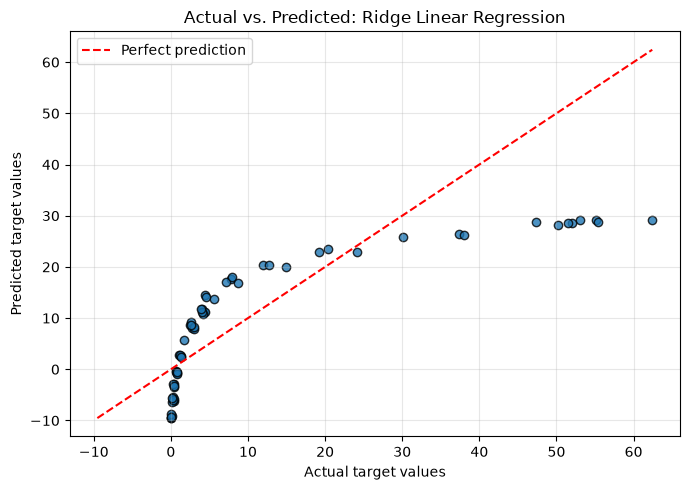

In [10]:
# Visualize the test-set predictions against the actual target values.
plot_min = min(float(np.min(y_test)), float(np.min(y_pred)))
plot_max = max(float(np.max(y_test)), float(np.max(y_pred)))

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, edgecolors="black", alpha=0.8)
plt.plot([plot_min, plot_max], [plot_min, plot_max], "r--", label="Perfect prediction")
plt.xlabel("Actual target values")
plt.ylabel("Predicted target values")
plt.title("Actual vs. Predicted: Ridge Linear Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Inspect the residuals

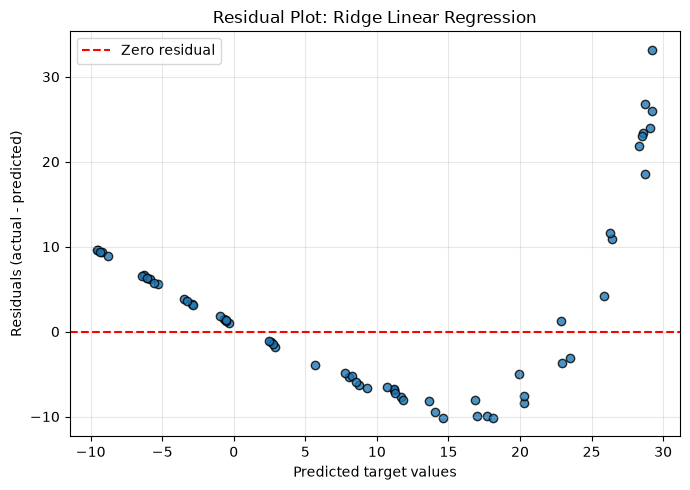

In [11]:
# Plot residuals against predicted values to check for visible patterns.
plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, edgecolors="black", alpha=0.8)
plt.axhline(0, color="red", linestyle="--", label="Zero residual")
plt.xlabel("Predicted target values")
plt.ylabel("Residuals (actual - predicted)")
plt.title("Residual Plot: Ridge Linear Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()